# 05 — Final evaluation: random test, leave-one-donor-out, leave-one-site-out

The design, metrics and expectations were fixed in the README **before** any result: the pre-registration
addendum, commit `fa39914`. This notebook runs that design once.

* **R**: random split, test part, evaluated **once**. Ridge 3a is refit on the training part; the MLP
  uses the three Phase 4 checkpoints (seeds 0-2).
* **D**: leave-one-donor-out, 9 folds. **C**: leave-one-site-out, 4 folds. Frozen hyperparameters; every
  learned step (HVG, scaling, PCA, ridge, target scaling) is refit on the fold's training cells only.
  MLP: 1 seed, early stopping on an inner 15% of the fold's training cells.
* Metric 1: within cell type x sample Pearson. Metric 2: standardized bias per (cell type x test sample),
  cell-weighted mean |b| and shift captured = 1 - Σ|b|(model) / Σ|b|(cell-type mean); cell types missing
  from training are excluded and counted. Metric 3: pooled within cell type Pearson, only for test sets
  with >= 2 samples.
* After this run **no setting and no mapping is changed**.

Smoke-test mode (`CITESEQ_SUBSET`) uses only random-split train/val cells, with **shuffled protein
targets**. It exercises the code without producing any real result.

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from citeseq.paths import RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR
from citeseq.data_prep import load_all
from citeseq.splits import load_split, make_random_split, group_folds
from citeseq.phase5 import fit_predict_fold, group_bias, weighted_abs_bias, shift_captured
from citeseq.correlation import within_group_pearson, summarize_within
from citeseq.metrics import evaluate
from citeseq import plotting as P

torch.set_num_threads(8)
SUBSET = int(os.environ.get("CITESEQ_SUBSET", 0)) or None
MAX_EPOCHS = int(os.environ.get("CITESEQ_MAX_EPOCHS", 200))
MIN_CELLS = 50
cfg3 = json.loads((RESULTS_DIR / "phase3_frozen_configs.json").read_text())
cfg4 = json.loads((RESULTS_DIR / "phase4_frozen_config.json").read_text())
OUT = PROCESSED_DIR / ("phase5" if SUBSET is None else "test_phase5")
OUT.mkdir(parents=True, exist_ok=True)
OUT_FIG = FIGURES_DIR if SUBSET is None else OUT / "figures"
OUT_FIG.mkdir(parents=True, exist_ok=True)
P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)
print("subset:", SUBSET, "| max epochs:", MAX_EPOCHS)

subset: None | max epochs: 200


## 1. Data and splits

In [2]:
split_full = None
mask = None
if SUBSET:
    # smoke test: only random-split train/val cells (never the test part), targets shuffled
    from citeseq.paths import CITE_H5AD
    from citeseq.io import _read_dataframe
    import h5py
    with h5py.File(CITE_H5AD) as f:
        names = _read_dataframe(f["obs"]).index
    split_full = load_split(RESULTS_DIR / "splits/random_split.csv.gz", names)
    rng = np.random.default_rng(0)
    pool = np.flatnonzero((split_full != "test").to_numpy())
    mask = np.zeros(len(names), bool); mask[rng.choice(pool, SUBSET, replace=False)] = True
d = load_all(cell_mask=mask)
X, Y, R, obs, proteins, pmap, genes = d["X"], d["Y"], d["R"], d["obs"], d["proteins"], d["pmap"], d["gene_names"]
if SUBSET:
    Y = Y[np.random.default_rng(1).permutation(len(Y))]          # no real signal in smoke tests
    split = make_random_split(obs, seed=0)
else:
    split = load_split(RESULTS_DIR / "splits/random_split.csv.gz", obs.index)
primary_cols = np.flatnonzero((pmap["analysis_set"] == "primary").to_numpy())
ct = obs["cell_type"].astype(str).to_numpy()
sample = obs["batch"].astype(str).to_numpy()
donor = obs["DonorNumber"].astype(str).to_numpy()
site = obs["Site"].astype(str).to_numpy()
type_sample = np.char.add(np.char.add(ct.astype(str), " | "), sample.astype(str))

folds = {("R", "random"): ((split == "train").to_numpy(), (split == "test").to_numpy())}
for g, te in group_folds(obs, "DonorNumber").items():
    folds[("D", g)] = (~te, te)
for g, te in group_folds(obs, "Site").items():
    folds[("C", g)] = (~te, te)
print(X.shape, "| folds:", [f"{k[0]}:{k[1]}" for k in folds])

(90261, 13953) | folds: ['R:random', 'D:donor1', 'D:donor2', 'D:donor3', 'D:donor4', 'D:donor5', 'D:donor6', 'D:donor7', 'D:donor8', 'D:donor9', 'C:site1', 'C:site2', 'C:site3', 'C:site4']


## 2. Fit and predict per fold (saved to disk; a finished fold is re-used)

In [3]:
def p4_ckpt(seed):
    b = cfg4["best"]
    key = json.dumps([b["hidden"], b["dropout"], b["weight_decay"], seed, 200, 15])
    return PROCESSED_DIR / "phase4_checkpoints" / f"mlp_{hashlib.md5(key.encode()).hexdigest()[:10]}.pt"

results = {}
t_all = time.time()
for (sp_name, fold), (train, test) in folds.items():
    f = OUT / f"{sp_name}_{fold}.npz"
    if f.exists():
        z = np.load(f, allow_pickle=True)
        results[(sp_name, fold)] = {"preds": z["preds"].item(), "state": z["state"].item()}
        print(f"{sp_name}:{fold:<8} loaded")
        continue
    t = time.time()
    if sp_name == "R":
        kw = dict(mlp_seeds=(0, 1, 2), mlp_val=(split == "val").to_numpy(),
                  checkpoint_fn=None if SUBSET else p4_ckpt)
    else:
        kw = dict(mlp_seeds=(0,), checkpoint_fn=lambda s, sp_name=sp_name, fold=fold: OUT / f"mlp_{sp_name}_{fold}_s{s}.pt")
    preds, state = fit_predict_fold(X, Y, R, obs, genes, train, test, cfg3, cfg4, max_epochs=MAX_EPOCHS, **kw)
    if sp_name == "R" and not SUBSET:
        assert all(v["loaded"] for v in state["mlp"].values()), "Phase 4 checkpoints were not re-used"
    np.savez_compressed(f, preds=np.array(preds, dtype=object), state=np.array(state, dtype=object))
    results[(sp_name, fold)] = {"preds": preds, "state": state}
    print(f"{sp_name}:{fold:<8} train {train.sum():>6,} test {test.sum():>6,} | MLP fit/stop {state['n_mlp_fit']:,}/{state['n_mlp_stop']:,} "
          f"| MLP {state['mlp']} | {(time.time() - t) / 60:.1f} min")
print(f"all folds: {(time.time() - t_all) / 60:.1f} min")

R:random   loaded


D:donor1   loaded
D:donor2   loaded
D:donor3   loaded


D:donor4   loaded
D:donor5   loaded


D:donor6   loaded
D:donor7   loaded


D:donor8   loaded
D:donor9   loaded


C:site1    loaded


C:site2    loaded


C:site3    loaded


C:site4    loaded
all folds: 0.1 min


## 3. Metrics

In [4]:
def mlp_keys(preds):
    return sorted(k for k in preds if k.startswith("MLP"))

def models_of(preds):
    return ["cell-type mean", "own gene", "ridge 3a"] + mlp_keys(preds)

rows, bias_long, r_long, excl_rows = [], [], [], []
for (sp_name, fold), res in results.items():
    train, test = folds[(sp_name, fold)]
    preds, state = res["preds"], res["state"]
    te = np.flatnonzero(test)
    yt = Y[te]
    seen = np.isin(ct[te], state["train_types"])
    excl_types = sorted(set(ct[te][~seen]))
    excl_rows.append({"split": sp_name, "fold": fold, "excluded_types": len(excl_types),
                      "excluded_cells": int((~seen).sum()), "types": ", ".join(excl_types)})
    # report groups: C folds are split into donor1 vs other donors
    subsets = {"all": np.ones(len(te), bool)}
    if sp_name == "C":
        subsets = {"donor1": donor[te] == "donor1", "other donors": donor[te] != "donor1"}
    for sub_name, sub in subsets.items():
        ref = group_bias(yt, preds["cell-type mean"], type_sample[te], state["sd_train"], MIN_CELLS, keep=sub & seen)
        n_samples = len(set(sample[te][sub]))
        for m in models_of(preds):
            p = preds[m]
            lb = group_bias(yt, p, type_sample[te], state["sd_train"], MIN_CELLS, keep=sub & seen)
            bias_long.append(lb.assign(split=sp_name, fold=fold, subset=sub_name, model=m))
            if sub.sum() and m != "cell-type mean":
                rl = within_group_pearson(p[sub], yt[sub], type_sample[te][sub], MIN_CELLS)
                r_long.append(rl.assign(split=sp_name, fold=fold, subset=sub_name, model=m))
            e_ts = evaluate(yt[sub], p[sub], type_sample[te][sub], proteins, MIN_CELLS)
            e_t = evaluate(yt[sub], p[sub], ct[te][sub], proteins, MIN_CELLS)
            rows.append({"split": sp_name, "fold": fold, "subset": sub_name, "model": m, "cells": int(sub.sum()),
                         "samples": n_samples,
                         "M1 within type x sample": e_ts["within_w"].iloc[primary_cols].median(),
                         "n type x sample groups": int(e_ts["n_types"].median()),
                         "M2 mean |b|": weighted_abs_bias(lb, primary_cols),
                         "M2 shift captured": shift_captured(lb, ref, primary_cols) if m != "cell-type mean" else np.nan,
                         "M3 pooled within type": e_t["within_w"].iloc[primary_cols].median() if n_samples >= 2 else np.nan,
                         "pearson all cells": e_t["pearson_all"].iloc[primary_cols].median()})
per_fold = pd.DataFrame(rows)
excluded = pd.DataFrame(excl_rows)
bias_long = pd.concat(bias_long, ignore_index=True)
r_long = pd.concat(r_long, ignore_index=True)
print("cell types excluded from metric 2 (absent from the fold's training cells):")
excluded[excluded["excluded_types"] > 0]

.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


... (10 outputs left out)

.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


cell types excluded from metric 2 (absent from the fold's training cells):


,split,fold,excluded_types,excluded_cells,types
2,D,donor2,1,42,CD8+ T naive CD127+ CD26- CD101-
7,D,donor7,2,42,"T prog cycling, cDC1"
10,C,site1,2,135,"CD4+ T CD314+ CD45RA+, CD8+ T naive CD127+ CD2..."
12,C,site3,2,42,"T prog cycling, cDC1"


### Report groups

* **R test**: random split; samples seen in training.
* **D, donors 2-9**: unseen donor; its site is seen (through donor1 and the other donor there). 8 folds
  pooled.
* **D, donor1**: unseen donor (4 samples), all sites seen through other donors.
* **C, donor1 cells**: donor seen, site unseen. **C, other donors**: donor and site unseen. 4 folds pooled.

Pooled numbers combine the per-fold (group, protein) pairs. Metric 1 is summarized over the pooled groups,
metric 2 over the pooled sums, and metric 3 is reported per fold.

In [5]:
def report_group(sp_name, folds_sel, subset):
    sel_b = (bias_long["split"] == sp_name) & bias_long["fold"].isin(folds_sel) & (bias_long["subset"] == subset)
    sel_r = (r_long["split"] == sp_name) & r_long["fold"].isin(folds_sel) & (r_long["subset"] == subset)
    out = {}
    lb_ref = bias_long[sel_b & (bias_long["model"] == "cell-type mean")]
    lb_ref_u = lb_ref.assign(group=lb_ref["fold"] + "/" + lb_ref["group"])
    for m in sorted(bias_long.loc[sel_b, "model"].unique()):
        lb = bias_long[sel_b & (bias_long["model"] == m)]
        lb_u = lb.assign(group=lb["fold"] + "/" + lb["group"])
        rl = r_long[sel_r & (r_long["model"] == m)]
        m1 = np.nan
        if len(rl):
            rl_u = rl.assign(group=rl["fold"] + "/" + rl["group"])
            s = summarize_within(rl_u, len(proteins))
            m1 = s["weighted_mean"].iloc[primary_cols].median()
        out[m] = {"M1 within type x sample": m1,
                  "M2 mean |b|": weighted_abs_bias(lb_u, primary_cols),
                  "M2 shift captured": shift_captured(lb_u[["group", "j", "n", "b"]], lb_ref_u[["group", "j", "n", "b"]], primary_cols)
                                       if m != "cell-type mean" else np.nan,
                  "type x sample groups": lb_u["group"].nunique()}
    return pd.DataFrame(out).T

donors29 = [f"donor{i}" for i in range(2, 10)]
sites = sorted(set(site))
groups_def = {
    "R test": ("R", ["random"], "all"),
    "D donors 2-9": ("D", donors29, "all"),
    "D donor1": ("D", ["donor1"], "all"),
    "C donor1 cells": ("C", sites, "donor1"),
    "C other donors": ("C", sites, "other donors"),
}
report = pd.concat({k: report_group(*v) for k, v in groups_def.items()}, names=["report group", "model"])
report

M1 within type x sample  M2 mean |b|  \
report group   model                                                  
R test         MLP s0                            0.105        0.116   
               MLP s1                            0.110        0.114   
               MLP s2                            0.112        0.117   
               cell-type mean                      NaN        0.307   
               own gene                          0.063        0.473   
               ridge 3a                          0.099        0.176   
D donors 2-9   MLP s0                            0.131        0.262   
               cell-type mean                      NaN        0.349   
               own gene                          0.065        0.496   
               ridge 3a                          0.122        0.287   
D donor1       MLP s0                            0.121        0.306   
               cell-type mean                      NaN        0.390   
               own gene                          0.062        0.523   
               ridge 3a                          0.108        0.335   
C donor1 cells MLP s0                            0.113        0.475   
               cell-type mean                      NaN        0.490   
               own gene                          0.062        0.587   
               ridge 3a                          0.109        0.466   
C other donors MLP s0                            0.118        0.401   
               cell-type mean                      NaN        0.429   
               own gene                          0.065        0.541   
               ridge 3a                          0.119        0.400   

                               M2 shift captured  type x sample groups  
report group   model                                                    
R test         MLP s0                      0.620                72.000  
               MLP s1                      0.630                72.000  
               MLP s2                      0.619                72.000  
               cell-type mean                NaN                72.000  
               own gene                   -0.543                72.000  
               ridge 3a                    0.425                72.000  
D donors 2-9   MLP s0                      0.250               192.000  
               cell-type mean                NaN               192.000  
               own gene                   -0.420               192.000  
               ridge 3a                    0.177               192.000  
D donor1       MLP s0                      0.215               104.000  
               cell-type mean                NaN               104.000  
               own gene                   -0.342               104.000  
               ridge 3a                    0.140               104.000  
C donor1 cells MLP s0                      0.030               104.000  
               cell-type mean                NaN               104.000  
               own gene                   -0.199               104.000  
               ridge 3a                    0.049               104.000  
C other donors MLP s0                      0.066               191.000  
               cell-type mean                NaN               191.000  
               own gene                   -0.260               191.000  
               ridge 3a                    0.069               191.000

In [6]:
# MLP on R: mean ± SD over the 3 seeds (D and C use seed 0 only)
r_mlp = report.loc["R test"].loc[[k for k in report.loc["R test"].index if k.startswith("MLP")]]
print("R test, MLP over seeds 0-2: mean"); print(r_mlp.mean(numeric_only=True).round(4).to_string())
print("SD"); print(r_mlp.std(numeric_only=True, ddof=1).round(4).to_string())

R test, MLP over seeds 0-2: mean
M1 within type x sample    0.109
M2 mean |b|                0.116
M2 shift captured          0.623
type x sample groups      72.000
SD
M1 within type x sample   0.004
M2 mean |b|               0.002
M2 shift captured         0.006
type x sample groups      0.000


In [7]:
print("Metric 3, pooled within cell type (test sets with >= 2 samples), and Pearson over all cells:")
m3 = per_fold[per_fold["samples"] >= 2][["split", "fold", "subset", "model", "samples", "cells",
                                          "M3 pooled within type", "pearson all cells"]]
m3

Metric 3, pooled within cell type (test sets with >= 2 samples), and Pearson over all cells:


,split,fold,subset,model,samples,cells,M3 pooled within type,pearson all cells
0,R,random,all,cell-type mean,12,13540,NaN,0.643
1,R,random,all,own gene,12,13540,0.075,0.292
2,R,random,all,ridge 3a,12,13540,0.338,0.736
3,R,random,all,MLP s0,12,13540,0.443,0.793
4,R,random,all,MLP s1,12,13540,0.442,0.791
5,R,random,all,MLP s2,12,13540,0.445,0.792
6,D,donor1,all,cell-type mean,4,30669,NaN,0.626
7,D,donor1,all,own gene,4,30669,0.069,0.251
8,D,donor1,all,ridge 3a,4,30669,0.201,0.695
9,D,donor1,all,MLP s0,4,30669,0.269,0.735


In [8]:
print("Per fold, ridge 3a and MLP seed 0:")
per_fold[per_fold["model"].isin(["ridge 3a", "MLP s0", "cell-type mean"])][
    ["split", "fold", "subset", "model", "cells", "samples", "M1 within type x sample", "M2 mean |b|", "M2 shift captured"]]

Per fold, ridge 3a and MLP seed 0:


,split,fold,subset,model,cells,samples,M1 within type x sample,M2 mean |b|,M2 shift captured
0,R,random,all,cell-type mean,13540,12,NaN,0.307,NaN
2,R,random,all,ridge 3a,13540,12,0.099,0.176,0.425
3,R,random,all,MLP s0,13540,12,0.105,0.116,0.620
6,D,donor1,all,cell-type mean,30669,4,NaN,0.390,NaN
8,D,donor1,all,ridge 3a,30669,4,0.108,0.335,0.140
9,D,donor1,all,MLP s0,30669,4,0.121,0.306,0.215
10,D,donor2,all,cell-type mean,4978,1,NaN,0.551,NaN
12,D,donor2,all,ridge 3a,4978,1,0.181,0.344,0.375
13,D,donor2,all,MLP s0,4978,1,0.204,0.288,0.478
14,D,donor3,all,cell-type mean,6106,1,NaN,0.458,NaN


### Metric 3 for the whole site folds (added after the first run)

The pre-registration asks for metric 3 on each site fold as a whole (3 test samples). The first run only
computed it inside the donor1 / other-donor subsets. This cell adds the missing pre-registered numbers
from the saved predictions. No model was refit and nothing else changed.

In [9]:
rows_m3 = []
for site_name in sorted(set(site)):
    res = results[("C", site_name)]
    te = np.flatnonzero(folds[("C", site_name)][1])
    for m in models_of(res["preds"]):
        e_t = evaluate(Y[te], res["preds"][m], ct[te], proteins, MIN_CELLS)
        rows_m3.append({"fold": site_name, "model": m, "samples": len(set(sample[te])), "cells": len(te),
                        "M3 pooled within type": e_t["within_w"].iloc[primary_cols].median(),
                        "pearson all cells": e_t["pearson_all"].iloc[primary_cols].median()})
m3_sites = pd.DataFrame(rows_m3)
print("mean over the 4 site folds:")
print(m3_sites.groupby("model")[["M3 pooled within type", "pearson all cells"]].mean().round(3).to_string())
m3_sites

.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


mean over the 4 site folds:
                M3 pooled within type  pearson all cells
model                                                   
MLP s0                          0.118              0.646
cell-type mean                    NaN              0.641
own gene                        0.072              0.312
ridge 3a                        0.126              0.648


,fold,model,samples,cells,M3 pooled within type,pearson all cells
0,site1,cell-type mean,3,16311,NaN,0.797
1,site1,own gene,3,16311,0.095,0.420
2,site1,ridge 3a,3,16311,0.151,0.810
3,site1,MLP s0,3,16311,0.150,0.829
4,site2,cell-type mean,3,25171,NaN,0.612
5,site2,own gene,3,25171,0.052,0.255
6,site2,ridge 3a,3,25171,0.100,0.600
7,site2,MLP s0,3,25171,0.097,0.582
8,site3,cell-type mean,3,32029,NaN,0.453
9,site3,own gene,3,32029,0.035,0.176


## 4. Figures

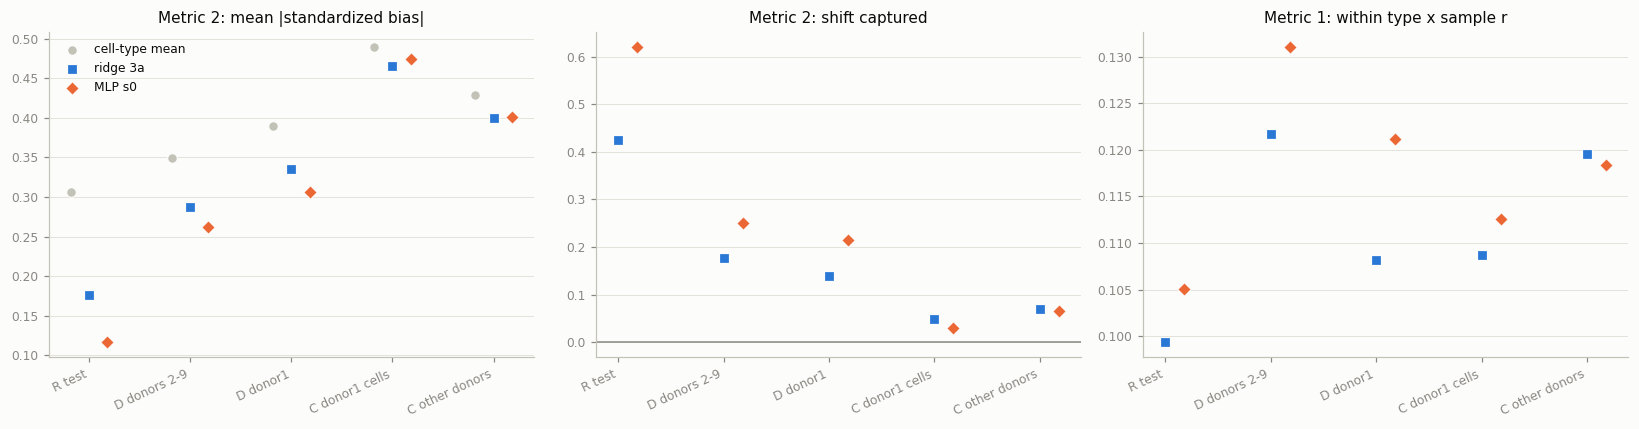

In [10]:
order = list(groups_def)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
series = [("cell-type mean", P.CONTEXT, "o"), ("ridge 3a", P.BLUE, "s"), ("MLP s0", P.ORANGE, "D")]
x = np.arange(len(order))
for ax, metric, title in zip(axes, ["M2 mean |b|", "M2 shift captured", "M1 within type x sample"],
                             ["Metric 2: mean |standardized bias|", "Metric 2: shift captured", "Metric 1: within type x sample r"]):
    for (m, colr, mk), off in zip(series, (-0.18, 0, 0.18)):
        vals = [report.loc[(g, m), metric] if (g, m) in report.index else np.nan for g in order]
        if np.all(np.isnan(np.asarray(vals, dtype=float))):
            continue
        ax.scatter(x + off, vals, color=colr, marker=mk, s=40, label=m, edgecolors=P.SURFACE, linewidths=0.8, zorder=3)
    ax.set_xticks(x, order, rotation=25, ha="right"); ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8)
axes[1].axhline(0, color=P.MUTED, lw=1)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase5_bias_shift.png")

In [11]:
if SUBSET is None:
    per_fold.to_csv(RESULTS_DIR / "phase5_per_fold.csv", index=False)
    report.reset_index().to_csv(RESULTS_DIR / "phase5_report_groups.csv", index=False)
    excluded.to_csv(RESULTS_DIR / "phase5_excluded_cell_types.csv", index=False)
    m3_sites.to_csv(RESULTS_DIR / "phase5_m3_site_folds.csv", index=False)
import resource, platform
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
print(f"peak memory: {(peak / 1e9 if platform.system() == 'Darwin' else peak * 1024 / 1e9):.2f} GB")

peak memory: 3.09 GB


## Findings: checked against the pre-registered expectations (README, commit `fa39914`)

Primary set (110 proteins). Ridge 3a; MLP = seed 0 in D/C, mean of 3 seeds on R (SD <= 0.006).

| Report group | Metric 1, within type x sample: ridge / MLP | mean abs. b: cell-type mean / ridge / MLP | shift captured: ridge / MLP |
|---|---|---|---|
| R test (samples seen) | 0.099 / 0.109 | 0.307 / 0.176 / 0.116 | **0.43 / 0.62** |
| D donors 2-9 (donor unseen, site seen) | 0.122 / 0.131 | 0.349 / 0.287 / 0.262 | 0.18 / 0.25 |
| D donor1 (donor unseen, sites seen) | 0.108 / 0.121 | 0.390 / 0.335 / 0.306 | 0.14 / 0.22 |
| C donor1 cells (donor seen, site unseen) | 0.109 / 0.113 | 0.490 / 0.466 / 0.475 | **0.05 / 0.03** |
| C other donors (both unseen) | 0.119 / 0.118 | 0.429 / 0.400 / 0.401 | **0.07 / 0.07** |

**Expectation by expectation**
* **Metric 1 ("about 0.10 everywhere, does not discriminate"): met.** 0.10-0.13 in all groups, no drop.
  The D/C groups contain more and different type x sample groups (104-192 vs 72), so small differences to
  R are not meaningful. The figure's narrow y-axis exaggerates them.
* **Metric 2, main test ("only C can contradict the sample-signature hypothesis"): not contradicted.**
  On unseen sites, ridge captures 5-7% of the sample shift and the MLP 3-7%, i.e. close to the cell-type
  mean baseline. On the random split they capture 43% and 62%. With an unseen donor but a seen site (D)
  they capture 14-25%, which is not informative about the hypothesis by the pre-registered rule.
* **Site vs. donor: mixed.**
  * D donor1 was predicted to show small |b| if the shift is site-driven. **Not met:** shift captured
    is only 0.14 (ridge). Its pooled within-type Pearson is clearly above 0.10 (ridge 0.20, MLP 0.27), which
    **is** met.
  * In C, donor1 cells were predicted to show similar |b| to the other donors if site-driven, and smaller
    if donor-driven. Observed: not smaller (ridge 0.47 vs 0.40; shift captured 0.05 vs 0.07). This is
    consistent with site-driven and does not support donor-driven.
  * The donor1 fold removes 34% of the training cells and the only donor that links sites (a
    pre-registered limitation). This may explain part of the D-donor1 result. Hypothesis.
* **Metric 3 ("on unseen sites clearly below 0.34 and closer to metric 1"): met.** Pooled within cell type
  on whole site folds (3 samples): ridge 0.151 / 0.100 / 0.068 / 0.186 (mean 0.126); MLP mean 0.118.
  Random split: ridge 0.338, MLP 0.443.

**Disclosed deviation:** metric 3 on whole site folds was missing from the first run and was added
afterwards from the saved predictions (cell above). Nothing was refit, and no setting or mapping was changed.

**Further observations (post hoc, descriptive)**
* **Ridge and MLP are equal on unseen sites.** The MLP's random-split advantage disappears there:
  overall Pearson 0.646 vs 0.648 (mean of site folds), shift captured 0.03-0.07 for both. This fits the
  Phase 4 observation that the MLP's extra gain was mostly at the sample level.
* **On unseen sites, RNA models hardly beat the label-based cell-type mean overall:** 0.648 (ridge) vs
  0.641. On the random test set the gap is 0.736 vs 0.643. They still predict within-sample variation
  (about 0.11-0.12), which the cell-type mean cannot.
* **Validation was hardly optimistic on the random split.** Test vs validation: ridge 0.736 vs 0.733,
  MLP 0.792 vs 0.794 (overall Pearson).
* **Overall Pearson depends strongly on the held-out site:** site1 0.81, site4 0.74, site2 0.60, site3 0.45
  (ridge). site2 and site3 are the sites with low ADT depth and a high isotype share (Phases 1-2). That
  their protein measurements are less predictable is a hypothesis.
* **Shift captured varies a lot between D folds** (ridge -0.05 for donor4 to 0.38 for donor2).
* Excluded from metric 2 (cell types missing from training): donor2 fold 1 type / 42 cells; donor7 2 / 42;
  site1 2 / 135; site3 2 / 42.

Runtime 33 min; peak memory 5.7 GB.